# DC4 511 keV parametric fit and temporal residuals

Fit the time-integrated DC4 observation with the parametric sky model from notebook 04, then build physical temporal predictions and analyze temporal residuals.


## Setup

Locate the workflow directory and import the tools used for the fit and temporal analysis.


In [1]:
# Locate the workflow directory whether the notebook starts inside it or in notebooks/.
from pathlib import Path
from time import perf_counter
import sys

working_dir = Path.cwd()
repo_root = working_dir.parent if working_dir.name == "notebooks" else working_dir
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Import numerical, plotting, astronomy, and fitting tools.
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.time import Time
from astromodels import (
    Asymm_Gaussian_on_sphere, ExtendedSource, Gaussian,
    Gaussian_on_sphere, LinearPolarization, Model, PointSource,
)
from histpy import Histogram
from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.response.ExtendedSourceResponse import ExtendedSourceResponse
from cosipy.response import (
    BinnedInstrumentResponse, BinnedThreeMLExtendedSourceResponse,
    BinnedThreeMLModelFolding, BinnedThreeMLPointSourceResponse,
)
from cosipy.statistics import PoissonLikelihood
from cosipy.interfaces import ThreeMLPluginInterface
from threeML import DataList, JointLikelihood
from src import path_to_files as paths
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals
from src.time_resolved_residuals_v1 import TimeResolvedResidualAnalysis

%matplotlib inline


## Load the observed counts

Combine the fourteen weekly 509–513 keV products while retaining `Time` to obtain the observed histogram $D_{t,i}$. Projecting it onto `(Em, Phi, PsiChi)` gives $D_i$ for the time-integrated fit.

In [2]:
# Combine the full weekly observations while retaining the Time axis.
observed_temporal_511_histogram = None
for week in sorted(paths.weekly_paths):
    weekly_path = paths.data_dir_out / f"dc4_week_{week}_511_binned.hdf5"
    weekly_data = BinnedData(paths.config_511_path)
    weekly_data.load_binned_data_from_hdf5(binned_data=str(weekly_path))
    weekly_data.get_binning_info()
    weekly_histogram = weekly_data.binned_data
    if observed_temporal_511_histogram is None:
        observed_temporal_511_histogram = weekly_histogram.copy()
    else:
        if weekly_histogram.axes != observed_temporal_511_histogram.axes:
            raise ValueError(f"Week {week} has incompatible time or CDS axes.")
        observed_temporal_511_histogram = observed_temporal_511_histogram + weekly_histogram

# Sum over time to obtain the observation for the integrated fit.
observed_511_histogram = (
    observed_temporal_511_histogram.project("Em", "Phi", "PsiChi")
    .to_dense(copy=False)
)

print("Observed temporal axes:", observed_temporal_511_histogram.axes.labels)
print("Observed temporal shape:", observed_temporal_511_histogram.shape)
print("Observed axes:", observed_511_histogram.axes.labels)
print("Observed shape:", observed_511_histogram.shape)
print("Observed total:", observed_511_histogram.contents.sum())

Observed temporal axes: ['Time' 'Em' 'Phi' 'PsiChi']
Observed temporal shape: (2217, 1, 60, 3072)
Observed axes: ['Em' 'Phi' 'PsiChi']
Observed shape: (1, 60, 3072)
Observed total: 1576953.0


## Load and check the simulated background

Keep the background-only simulation with its Time axis and project it onto CDS for the integrated fit. Its normalization will be fitted later. The DC4 simulated background can share events with the observed data, which matters when interpreting residuals.

In [3]:
# Keep the time-binned simulated background for later temporal analysis.
simulated_background_temporal_511_histogram = Histogram.open(
    paths.simulated_background_511_binned_path
)

# Sum over time to obtain the background used in the integrated fit.
simulated_background_511_histogram = (
    simulated_background_temporal_511_histogram
    .project("Em", "Phi", "PsiChi")
    .to_dense(copy=True)
)

# Verify compatible temporal and integrated axes before constructing the likelihood.
if observed_temporal_511_histogram.axes != simulated_background_temporal_511_histogram.axes:
    raise ValueError("Observed and background temporal axes do not match.")
if observed_511_histogram.axes != simulated_background_511_histogram.axes:
    raise ValueError("Observed and background CDS axes do not match.")
for name, histogram in (("Observed", observed_511_histogram), ("Background", simulated_background_511_histogram)):
    values = np.asarray(histogram.contents)
    if not np.all(np.isfinite(values)) or np.any(values < 0):
        raise ValueError(f"{name} counts must be finite and non-negative.")

print("Background temporal axes:", simulated_background_temporal_511_histogram.axes.labels)
print("Background temporal shape:", simulated_background_temporal_511_histogram.shape)
print("Background axes:", simulated_background_511_histogram.axes.labels)
print("Background shape:", simulated_background_511_histogram.shape)
print("Background total:", simulated_background_511_histogram.contents.sum())

Background temporal axes: ['Time' 'Em' 'Phi' 'PsiChi']
Background temporal shape: (2217, 1, 60, 3072)
Background axes: ['Em' 'Phi' 'PsiChi']
Background shape: (1, 60, 3072)
Background total: 1374985.0


## Define the parametric sky model

Following notebook 04, the model contains a central point source, a narrow bulge, a broad bulge, and a disk. Each has a Gaussian 511 keV line. The line centroids and widths are fixed because the response has one true-energy bin; the line fluxes and disk ellipticity are free. The initial fluxes are optimizer starting values, not fitted results.

In [4]:
# Give each component its own Gaussian line and free integrated flux.
component_names = ("centralPoint", "narrowBulge", "broadBulge", "disk")
line_centroids = np.full(4, 511.0) * u.keV
line_fwhm = np.array([2.0, 2.0, 2.0, 3.0]) * u.keV
line_widths = line_fwhm / (2.0 * np.sqrt(2.0 * np.log(2.0)))
initial_line_fluxes = [1.2e-4, 2.8e-4, 7.3e-4, 1.7e-3] / (u.cm**2 * u.s)
line_spectra = [Gaussian() for _ in component_names]
for spectrum, centroid, width, flux in zip(line_spectra, line_centroids, line_widths, initial_line_fluxes):
    spectrum.F.unit = flux.unit
    spectrum.F.value = flux.value
    spectrum.F.min_value = 0.0
    spectrum.F.free = True
    spectrum.mu.unit = centroid.unit
    spectrum.mu.value = centroid.value
    spectrum.mu.free = False
    spectrum.sigma.unit = width.unit
    spectrum.sigma.value = width.value
    spectrum.sigma.free = False

In [5]:
# Define the spatial components using the settings from notebook 04.
narrow_bulge = Gaussian_on_sphere(lon0=359.75, lat0=-1.25, sigma=2.5)
broad_bulge = Gaussian_on_sphere(lon0=0, lat0=0, sigma=8.7)
disk = Asymm_Gaussian_on_sphere(lon0=0, lat0=0, a=10, e=0.99944429, theta=0)
disk.a.max_value = 90
disk.a.value = 90
for bulge in (narrow_bulge, broad_bulge):
    bulge.lon0.free = False
    bulge.lat0.free = False
    bulge.sigma.free = False
disk.lon0.free = False
disk.lat0.free = False
disk.a.free = False
disk.e.free = True
disk.theta.free = False

# Fix each component to zero polarization, as in the reference fit.
def make_unpolarized_model():
    polarization = LinearPolarization(degree=0.0, angle=0.0)
    polarization.degree.free = False
    polarization.angle.free = False
    return polarization

# Convert the Galactic-center position to the point-source coordinates.
center = SkyCoord(l=0.0 * u.deg, b=0.0 * u.deg, frame="galactic").transform_to("icrs")
central_point_source = PointSource(
    "centralPoint", ra=center.ra.deg, dec=center.dec.deg,
    spectral_shape=line_spectra[0], polarization=make_unpolarized_model(),
)
narrow_bulge_source = ExtendedSource(
    "narrowBulge", spectral_shape=line_spectra[1], spatial_shape=narrow_bulge,
    polarization=make_unpolarized_model(),
)
broad_bulge_source = ExtendedSource(
    "broadBulge", spectral_shape=line_spectra[2], spatial_shape=broad_bulge,
    polarization=make_unpolarized_model(),
)
disk_source = ExtendedSource(
    "disk", spectral_shape=line_spectra[3], spatial_shape=disk,
    polarization=make_unpolarized_model(),
)
source_model_511 = Model(central_point_source, narrow_bulge_source, broad_bulge_source, disk_source)
source_model_511.display(complete=True)

Model summary:
==============

                  N
Point sources     1
Extended sources  3
Particle sources  0

Free parameters (5):
--------------------

                                          value min_value max_value      unit
centralPoint.spectrum.main.Gaussian.F   0.00012       0.0      None  s-1 cm-2
narrowBulge.spectrum.main.Gaussian.F    0.00028       0.0      None  s-1 cm-2
broadBulge.spectrum.main.Gaussian.F     0.00073       0.0      None  s-1 cm-2
disk.Asymm_Gaussian_on_sphere.e        0.999444       0.0       1.0          
disk.spectrum.main.Gaussian.F            0.0017       0.0      None  s-1 cm-2

Fixed parameters (28):
---------------------

                                               value min_value max_value unit
centralPoint.position.ra                  266.404988       0.0     360.0  deg
centralPoint.position.dec                 -28.936178     -90.0      90.0  deg
centralPoint.spectrum.main.Gaussian.mu         511.0      None      None  keV
centralPoint...sigma                        0.849322       0.0      None  keV
centralPoint...degree                            0.0       0.0     100.0     
centralPoint...angle                             0.0       0.0     180.0  deg
narrowBulge.Gaussian_on_sphere.lon0           359.75       0.0     360.0  deg
narrowBulge.Gaussian_on_sphere.lat0            -1.25     -90.0      90.0  deg
narrowBulge.Gaussian_on_sphere.sigma             2.5       0.0      20.0  deg
narrowBulge.spectrum.main.Gaussian.mu          511.0      None      None  keV
narrowBulge.spectrum.main.Gaussian.sigma    0.849322       0.0      None  keV
narrowBulge...degree                             0.0       0.0     100.0     
narrowBulge...angle                              0.0       0.0     180.0  deg
broadBulge.Gaussian_on_sphere.lon0               0.0       0.0     360.0  deg
broadBulge.Gaussian_on_sphere.lat0               0.0     -90.0      90.0  deg
broadBulge.Gaussian_on_sphere.sigma              8.7       0.0      20.0  deg
broadBulge.spectrum.main.Gaussian.mu           511.0      None      None  keV
broadBulge.spectrum.main.Gaussian.sigma     0.849322       0.0      None  keV
broadBulge...degree                              0.0       0.0     100.0     
broadBulge...angle                               0.0       0.0     180.0  deg
disk.Asymm_Gaussian_on_sphere.lon0               0.0       0.0     360.0  deg
disk.Asymm_Gaussian_on_sphere.lat0               0.0     -90.0      90.0  deg
disk.Asymm_Gaussian_on_sphere.a                 90.0       0.0      90.0  deg
disk.Asymm_Gaussian_on_sphere.theta              0.0     -90.0      90.0  deg
disk.spectrum.main.Gaussian.mu                 511.0      None      None  keV
disk.spectrum.main.Gaussian.sigma           1.273983       0.0      None  keV
disk.spectrum.main.polarization.degree           0.0       0.0     100.0     
disk.spectrum.main.polarization.angle            0.0       0.0     180.0  deg

Properties (0):
--------------------

(none)


Linked parameters (0):
----------------------

(none)

Independent variables:
----------------------

(none)

Linked functions (0):
----------------------

(none)

## Prepare the response and likelihood

The fit uses time-integrated CDS counts. The point-source response uses the spacecraft history, and extended sources use the precomputed extended response. The simulated background has one free normalization, following notebook 04.

In [6]:
# Load the observing history and both response products.
data_511 = EmCDSBinnedData(observed_511_histogram)
spacecraft_history = SpacecraftHistory.open(paths.data_ori_path)
extended_response_511 = ExtendedSourceResponse.open(paths.data_ext_response511_path)
full_response_511 = FullDetectorResponse.open(paths.data_response511_path)
instrument_response_511 = BinnedInstrumentResponse(full_response_511, data_511)

# Check that each response predicts the same CDS bins as the data.
if extended_response_511.axes[2:] != data_511.axes:
    raise ValueError("Extended response and observed CDS axes do not match.")
if instrument_response_511.axes != data_511.axes:
    raise ValueError("Point-source response and observed CDS axes do not match.")
print("Response and observed CDS axes are compatible.")

Response and observed CDS axes are compatible.


In [7]:
# Copy the background because its model normalizes the histogram in place.
background_distribution = {"background": simulated_background_511_histogram.copy()}
background_distribution["background"] += sys.float_info.min
background_model_511 = FreeNormBinnedBackground(
    background_distribution, sc_history=spacecraft_history, copy=False
)
# Set the initial background rate; the likelihood will fit its normalization.
initial_background_rate = (
    float(np.asarray(simulated_background_511_histogram.contents).sum())
    / spacecraft_history.cumulative_livetime()
).to(u.Hz)
background_model_511.set_norm({"background": initial_background_rate})
if background_model_511.axes != data_511.axes:
    raise ValueError("Background model and observed CDS axes do not match.")

# Fold point and extended sources through their corresponding responses.
extended_source_response_511 = BinnedThreeMLExtendedSourceResponse(
    data=data_511, precomputed_psr=extended_response_511
)
point_source_response_511 = BinnedThreeMLPointSourceResponse(
    data=data_511, instrument_response=instrument_response_511,
    sc_history=spacecraft_history, energy_axis=extended_response_511.axes["Ei"],
    polarization_axis=(extended_response_511.axes["Pol"] if "Pol" in extended_response_511.axes.labels else None),
    nside=2 * data_511.axes["PsiChi"].nside,
)
model_folding_511 = BinnedThreeMLModelFolding(
    data=data_511, point_source_response=point_source_response_511,
    extended_source_response=extended_source_response_511,
)

# Construct the Poisson likelihood and expose it to 3ML.
poisson_likelihood_511 = PoissonLikelihood(
    data=data_511, response=model_folding_511, bkg=background_model_511
)
cosi_plugin_511 = ThreeMLPluginInterface(
    name="cosi_511", likelihood=poisson_likelihood_511,
    response=model_folding_511, bkg=background_model_511,
)
cosi_plugin_511.bkg_parameter["background"].min_value = 0.0
likelihood_511 = JointLikelihood(source_model_511, DataList(cosi_plugin_511), verbose=False)
print("Initial background rate:", background_model_511.norm)

Initial background rate: 0.20897841875324394 Hz


## Fit the model

Optimize the free source parameters and background normalization using the integrated observation. This calculation can take time. Inspect the fit output and warnings before interpreting the results.

In [8]:
# Run the fit and display the resulting parameter estimates.
likelihood_511.fit()
fit_results_511 = likelihood_511.results
fit_results_511.display()

The current value of parameter F is very close to its lower bound when starting the fit. Fixing it

WARNING UserWarning: 50.5% of samples have been thrown away because they failed the constraints on the parameters. This result might not be suitable for error propagation. Enlarge the boundaries until you lose less than 1% ofthe samples.
Discarded samples in excluded parameter space (2524 samples):
  F: mean=0.001481, std=4.386e-05, bounds=[0, inf]
  F: mean=-2.798e-07, std=2.083e-07, bounds=[0, inf]
  F: mean=0.0002378, std=6.164e-05, bounds=[0, inf]
  e: mean=0.9972, std=0.0004765, bounds=[0, 1]
  F: mean=0.003387, std=7.07e-05, bounds=[0, inf]
  background: mean=0.2117, std=0.0003665, bounds=[0, inf]



Best fit values:

,result,unit
parameter,,
centralPoint.spectrum.main.Gaussian.F,(1.48 +/- 0.04) x 10^-3,1 / (s cm2)
narrowBulge.spectrum.main.Gaussian.F,(0.0 +/- 3.5) x 10^-7,1 / (s cm2)
broadBulge.spectrum.main.Gaussian.F,(2.4 +/- 0.6) x 10^-4,1 / (s cm2)
disk.Asymm_Gaussian_on_sphere.e,(9.972 +/- 0.005) x 10^-1,
disk.spectrum.main.Gaussian.F,(3.39 +/- 0.07) x 10^-3,1 / (s cm2)
background,(2.117 +/- 0.004) x 10^-1,Hz


Correlation matrix:

1.00,-0.04,-0.85,-0.22,0.20,-0.06
-0.04,1.00,-0.01,-0.00,0.00,-0.00
-0.85,-0.01,1.00,0.23,-0.42,0.09
-0.22,-0.00,0.23,1.00,-0.46,0.37
0.20,0.00,-0.42,-0.46,1.00,-0.78
-0.06,-0.00,0.09,0.37,-0.78,1.00


Values of -log(likelihood) at the minimum:

... (7 outputs left out)

Values of -log(likelihood) at the minimum:

,-log(likelihood)
cosi_511,-2273337.2858025837
total,-2273337.2858025837


Values of statistical measures:

,statistical measures
AIC,-4546662.571149421
BIC,-4546601.825033229


## Construct the fitted expectation

Evaluate the fitted source and background in the integrated CDS bins. These products configure and check the physical temporal prediction.


In [9]:
# Evaluate the fitted source and background components.
source_expectation_511 = model_folding_511.expectation(copy=True)
background_expectation_511 = background_model_511.expectation(copy=True)
total_expectation_511 = source_expectation_511 + background_expectation_511

# Verify the expectation can be compared bin by bin with the observation.
if data_511.data.axes != total_expectation_511.axes:
    raise ValueError("Observed and fitted expectation axes do not match.")
if data_511.data.shape != total_expectation_511.shape:
    raise ValueError("Observed and fitted expectation shapes do not match.")
print("Observed total:", data_511.data.contents.sum())
print("Source expectation:", source_expectation_511.contents.sum())
print("Background expectation:", background_expectation_511.contents.sum())
print("Total expectation:", total_expectation_511.contents.sum())

Observed total: 1576953.0
Source expectation: 184210.99683670758
Background expectation: 1392745.4420690485
Total expectation: 1576956.438905756


## Test: physical temporal prediction for the parametric model

This section tests only `TimeResolvedResidualAnalysis`. It uses the fitted parametric sky model, the fitted background expectation, the original time-binned inputs, and the sky and energy axes of the response used in the fit. The class derives and checks the background scaling, folds the sources for the selected interval, and returns matching observed and expected histograms.

The first calculation can be slow because the extended-source response is evaluated pixel by pixel at the fitted sky resolution. The output remains provisional: these checks do not establish equivalence with the precomputed integrated response or validate the statistical interpretation of residuals. The figures below compare counts only; no residual analysis is performed in this section.

In [10]:
# Prepare the temporal builder with the fitted model and original time histograms.
temporal_test = TimeResolvedResidualAnalysis(
    observed=observed_temporal_511_histogram,
    integrated_expected=total_expectation_511,
)

# Use the optimized fit and the axes of the response used for extended sources.
temporal_test.configure_physical_model(
    fitted_model=fit_results_511.optimized_model,
    response_path=paths.data_response511_path,
    orientation=spacecraft_history,
    temporal_background=simulated_background_temporal_511_histogram,
    fitted_background=background_expectation_511,
    extended_sky_axis=extended_response_511.axes[0],
    fitted_energy_axis=extended_response_511.axes["Ei"],
    earth_occ=True,
)
print("Available original time bins:", temporal_test.observed_hist.axes["Time"].nbins)

Available original time bins: 2217


In [11]:
# Calculate one original time bin; the stop index is excluded.
test_time_bin_index = 13
test_start = perf_counter()
test_observed, test_expected = temporal_test.build_physical_time_range(
    start=test_time_bin_index, stop=test_time_bin_index + 1,
)

# Check the time and CDS axes and inspect the returned physical counts.
if test_observed.axes != test_expected.axes or test_observed.shape != test_expected.shape:
    raise ValueError("Observed and expected temporal histograms do not match.")
for name, histogram in (("Observed", test_observed), ("Expected", test_expected)):
    values = np.asarray(histogram.contents)
    if not np.all(np.isfinite(values)) or np.any(values < 0):
        raise ValueError(f"{name} counts must be finite and non-negative.")

In [12]:


print("Original time bin:", test_time_bin_index)
print("Time boundaries:", test_observed.axes["Time"].edges)
print("Matching axes:", test_observed.axes.labels)
print("Histogram shape:", test_observed.shape)
print("Observed total:", test_observed.contents.sum())
print("Expected total:", test_expected.contents.sum())
print("Calculation time (seconds):", perf_counter() - test_start)

Original time bin: 13
Time boundaries: [1.83553409e+09 1.83553769e+09] s
Matching axes: ['Time' 'Em' 'Phi' 'PsiChi']
Histogram shape: (1, 1, 60, 3072)
Observed total: 597
Expected total: 605.5310180564766
Calculation time (seconds): 177.8705021249989


### Counts versus Phi for one interval

Project the selected temporal bin onto `Phi` and compare observed and expected counts. The plot sums over energy and `PsiChi`; it does not calculate residuals.

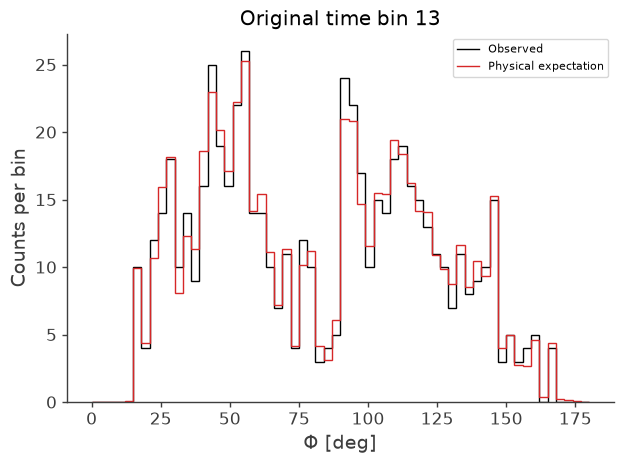

In [13]:
test_phi_observed = test_observed.project("Phi")
test_phi_expected = test_expected.project("Phi")
phi_edges = test_phi_observed.axes["Phi"].edges.to_value(u.deg)

# Compare observed and predicted counts in each Phi bin.
fig, ax = plt.subplots()
ax.stairs(np.asarray(test_phi_observed.contents), phi_edges, label="Observed", color="black")
ax.stairs(np.asarray(test_phi_expected.contents), phi_edges, label="Physical expectation", color="tab:red")
ax.set(xlabel=r"$\Phi$ [deg]", ylabel="Counts per bin", title=f"Original time bin {test_time_bin_index}")
ax.legend()
fig.tight_layout()
plt.show()

### Counts versus time for five intervals

Build five consecutive original time bins, starting with the interval above. The previously calculated bin is reused; the other four can take several minutes each. The plot selects the Phi bin containing 90 degrees, sums over energy and PsiChi, and shows the actual time boundaries in UTC.

In [ ]:
# Build five intervals, reusing any predictions already held in memory.
five_observed, five_expected = temporal_test.build_physical_time_range(
    start=test_time_bin_index, stop=test_time_bin_index + 5,
)
# Keep Time and Phi while summing over energy and PsiChi.
time_phi_observed = five_observed.project("Time", "Phi")
time_phi_expected = five_expected.project("Time", "Phi")
phi_edges = time_phi_observed.axes["Phi"].edges.to_value(u.deg)
# Select the Phi bin containing 90 degrees.
phi_bin_index = np.searchsorted(phi_edges, 90.0, side="right") - 1
if not 0 <= phi_bin_index < len(phi_edges) - 1:
    raise ValueError("90 degrees is outside the Phi axis.")
print(f"Selected Phi bin: {phi_edges[phi_bin_index]:.1f} to {phi_edges[phi_bin_index + 1]:.1f} deg")
time_edges = Time(time_phi_observed.axes["Time"].edges.to_value(u.s), format="unix", scale="utc")
date_edges = mdates.date2num(time_edges.to_datetime())

# Plot the observed and predicted evolution using the real bin boundaries.
fig, ax = plt.subplots()
ax.stairs(np.asarray(time_phi_observed.contents)[:, phi_bin_index], date_edges, label="Observed", color="black")
ax.stairs(np.asarray(time_phi_expected.contents)[:, phi_bin_index], date_edges, label="Physical expectation", color="tab:red")
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d %H:%M"))
ax.set(xlabel="Time (UTC)", ylabel="Counts per time bin", title=f"Counts over time, Phi {phi_edges[phi_bin_index]:.1f} to {phi_edges[phi_bin_index + 1]:.1f} deg")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Temporal residual analysis

Use the five observed and physical expected time bins constructed above. Residuals are calculated after projecting the counts. The physical prediction is provisional, and the shared simulated background means these plots alone are not a calibrated goodness-of-fit test. No uncertainty bands or Gaussian references are shown.

Observed data contain time information; using temporal residual analysis.


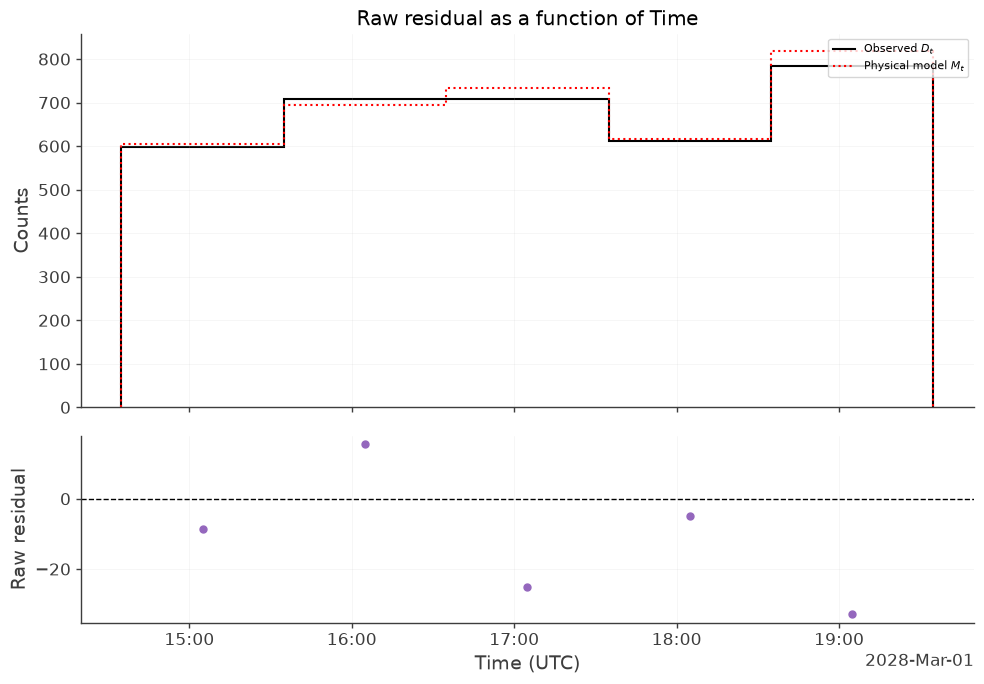

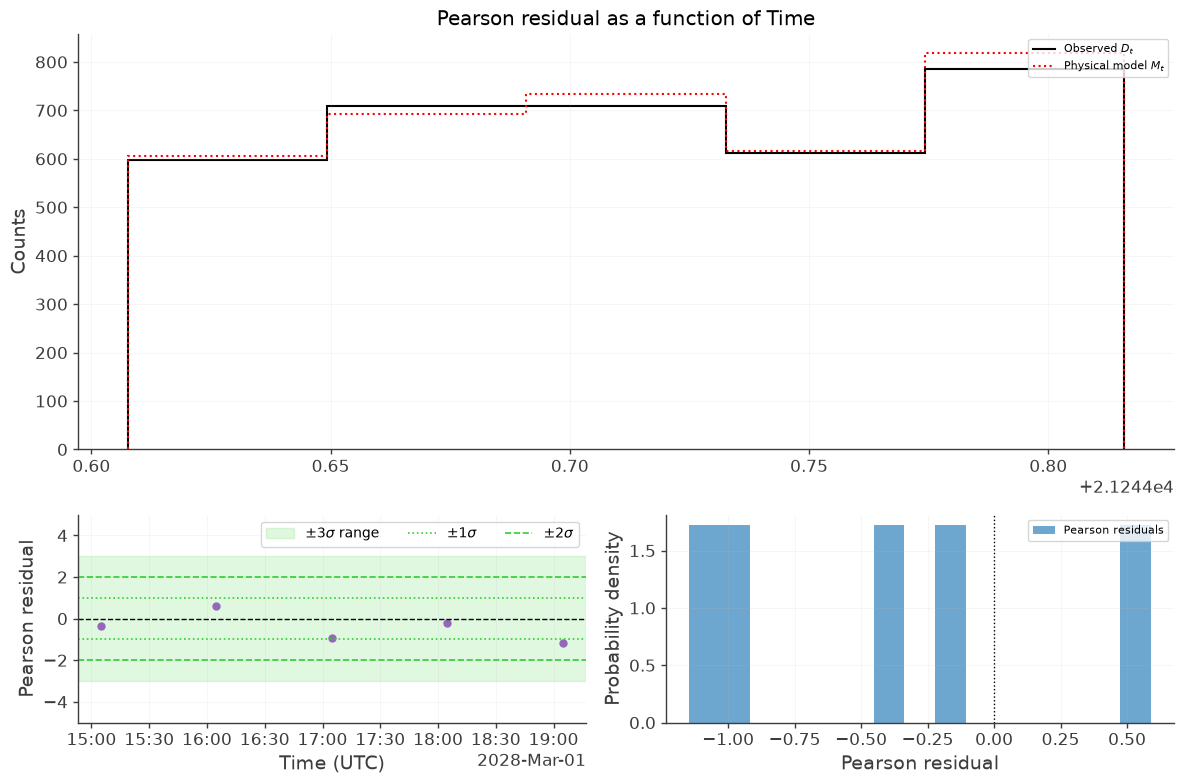

In [ ]:
# Analyze the five prepared intervals without rebuilding the physical model.
temporal_residual_analysis = ResidualAnalysis(
    observed=five_observed, expected=five_expected,
)
temporal_residual_plotter = PlottingResiduals(temporal_residual_analysis)

# Compare the total counts and raw residuals across the selected times.
time_raw_residual_figure = temporal_residual_plotter.plot(
    "Time_projection", residual_type="raw", show_uncertainty=False,
)

# Inspect the Pearson residuals without a reference distribution.
time_pearson_residual_figure = temporal_residual_plotter.plot(
    "Time_projection", residual_type="pearson",
    show_uncertainty=False, show_gaussian_reference=False,
)

### Residuals versus Phi in one interval

Select an interval from the five-bin histogram before making angular projections. Its index is local to this subset: local bin 0 is the original bin `test_time_bin_index`.

Local time bin: 0
Original time bin: 13


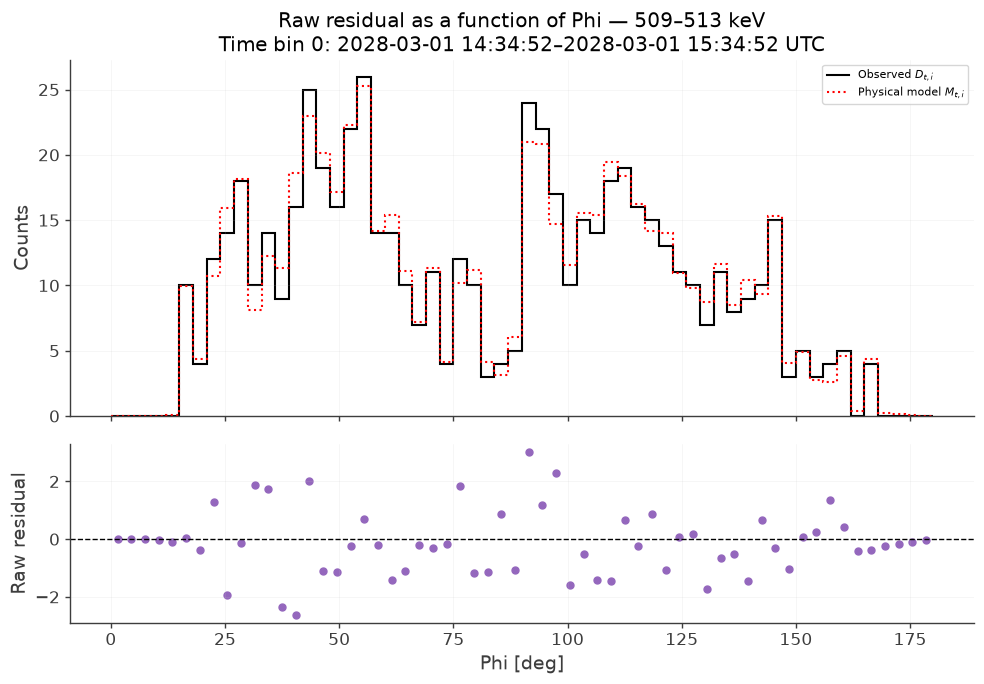

In [ ]:
# Select one already calculated interval using its local subset index.
local_time_bin_index = 0
selected_temporal_residuals = temporal_residual_analysis.select_time_bin(local_time_bin_index)
print("Local time bin:", local_time_bin_index)
print("Original time bin:", test_time_bin_index + local_time_bin_index)
selected_temporal_plotter = PlottingResiduals(selected_temporal_residuals)

# Plot counts and raw residuals against Phi without an uncertainty band.
phi_temporal_raw_figure = selected_temporal_plotter.plot(
    "Phi_projection", residual_type="raw", show_uncertainty=False,
)